# Exploration et modélisation avec Python

## Chargement et découverte des données

In [198]:
# %pip install pandas
# %pip install matplotlib
# %pip install seaborn

In [235]:
# Importer les bibliothèques
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_absolute_percentage_error
)

In [200]:
# Charger le dataset
df=pd.read_csv('data/PJME_hourly.csv')

In [201]:
# Convertir Datetime en format datetime
df['Datetime'] = pd.to_datetime(df['Datetime'])

In [202]:
# Explorer la structure des données
df.head()
df.tail()
df.shape
df.info()
df.dtypes

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145366 entries, 0 to 145365
Data columns (total 2 columns):
 #   Column    Non-Null Count   Dtype         
---  ------    --------------   -----         
 0   Datetime  145366 non-null  datetime64[ns]
 1   PJME_MW   145366 non-null  float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 2.2 MB


,0
Datetime,datetime64[ns]
PJME_MW,float64


In [203]:
# Explorer la structure des données
df.describe()

,Datetime,PJME_MW
count,145366,145366.000000
mean,2010-04-18 03:25:25.999202048,32080.222831
min,2002-01-01 01:00:00,14544.000000
25%,2006-02-23 14:15:00,27573.000000
50%,2010-04-18 04:30:00,31421.000000
75%,2014-06-10 18:45:00,35650.000000
max,2018-08-03 00:00:00,62009.000000
std,NaN,6464.012166


In [204]:
# Identifier les valeurs manquantes
df.isnull().sum()

,0
Datetime,0
PJME_MW,0


In [205]:
# Examiner la répartition temporelle
print("Date minimale :", df['Datetime'].min())
print("Date maximale :", df['Datetime'].max())

print("Nombre d'observations :", len(df))

Date minimale : 2002-01-01 01:00:00
Date maximale : 2018-08-03 00:00:00
Nombre d'observations : 145366


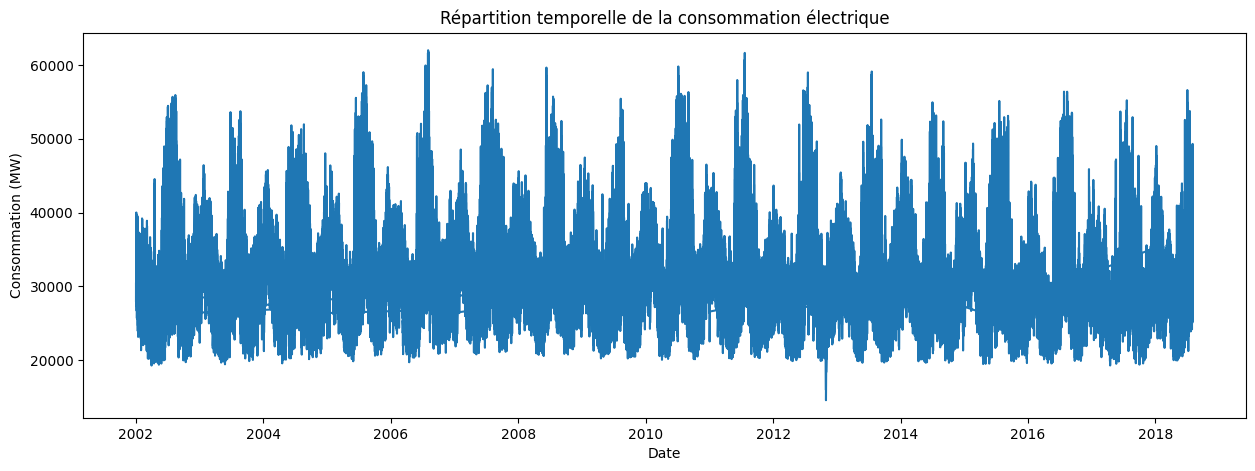

In [206]:
plt.figure(figsize=(15,5))

plt.plot(df['Datetime'], df['PJME_MW'])

plt.title("Répartition temporelle de la consommation électrique")
plt.xlabel("Date")
plt.ylabel("Consommation (MW)")

plt.show()

## Étape 2 : Nettoyage des données

In [207]:
# Vérifier les doublons
df.duplicated().sum()

np.int64(0)

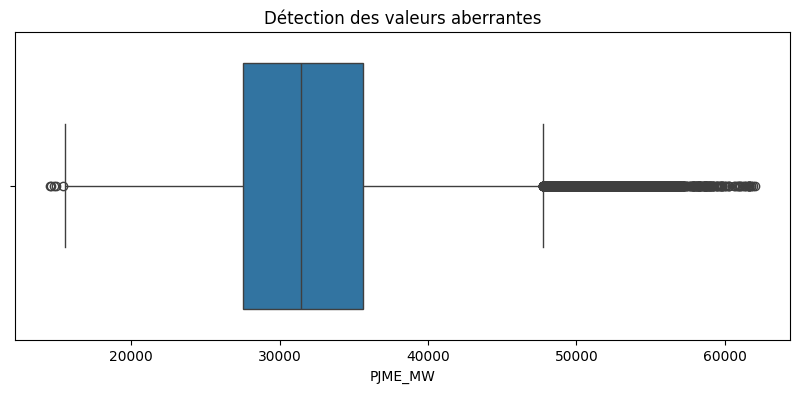

In [208]:
# Identifier les anomalies (Outliers)
plt.figure(figsize=(10,4))

sns.boxplot(x=df['PJME_MW'])

plt.title("Détection des valeurs aberrantes")

plt.show()

In [209]:
Q1 = df['PJME_MW'].quantile(0.25)
Q3 = df['PJME_MW'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df['PJME_MW'] < lower_bound) |
    (df['PJME_MW'] > upper_bound)
]

print("Nombre des outliers :", len(outliers))

Nombre des outliers : 3455


In [210]:
# Définir Datetime comme index
df = df.set_index('Datetime')

# Extraire les informations temporelles
df['Hour'] = df.index.hour
df['DayOfWeek'] = df.index.dayofweek
df['Month'] = df.index.month
df['Year'] = df.index.year

df['IsWeekend'] = (df['DayOfWeek'] >= 5).astype(int)


In [211]:
consumption_hour = df.groupby('Hour')['PJME_MW'].mean()

consumption_hour

,PJME_MW
Hour,
0,29523.611194
1,27535.589964
2,26344.055207
3,25679.097666
4,25414.924728
5,25749.431000
6,27162.853912
7,29611.046880
8,31490.827831


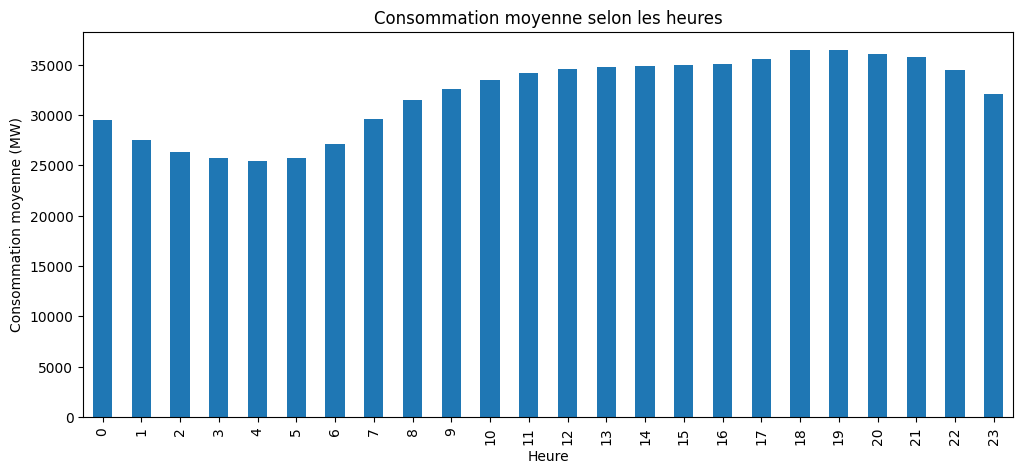

In [212]:
plt.figure(figsize=(12,5))

consumption_hour.plot(kind='bar')

plt.title("Consommation moyenne selon les heures")
plt.xlabel("Heure")
plt.ylabel("Consommation moyenne (MW)")

plt.show()

In [ ]:
# Étudier la consommation selon les jours
# df['Day'] = df.index.dayofweek

In [ ]:
# df['Day']

,Day
Datetime,
2002-12-31 01:00:00,1
2002-12-31 02:00:00,1
2002-12-31 03:00:00,1
2002-12-31 04:00:00,1
2002-12-31 05:00:00,1
...,...
2018-01-01 20:00:00,0
2018-01-01 21:00:00,0
2018-01-01 22:00:00,0


In [215]:
days = {
    0: 'Monday',
    1: 'Tuesday',
    2: 'Wednesday',
    3: 'Thursday',
    4: 'Friday',
    5: 'Saturday',
    6: 'Sunday'
}

df['Day_Name'] = df['Day'].map(days)

In [216]:
df

,PJME_MW,Hour,DayOfWeek,Month,Year,IsWeekend,Day,Day_Name
Datetime,,,,,,,,
2002-12-31 01:00:00,26498.0,1,1,12,2002,0,1,Tuesday
2002-12-31 02:00:00,25147.0,2,1,12,2002,0,1,Tuesday
2002-12-31 03:00:00,24574.0,3,1,12,2002,0,1,Tuesday
2002-12-31 04:00:00,24393.0,4,1,12,2002,0,1,Tuesday
2002-12-31 05:00:00,24860.0,5,1,12,2002,0,1,Tuesday
...,...,...,...,...,...,...,...,...
2018-01-01 20:00:00,44284.0,20,0,1,2018,0,0,Monday
2018-01-01 21:00:00,43751.0,21,0,1,2018,0,0,Monday
2018-01-01 22:00:00,42402.0,22,0,1,2018,0,0,Monday


In [217]:
consumption_day = df.groupby('Day_Name')['PJME_MW'].mean()
consumption_day

,PJME_MW
Day_Name,
Friday,32688.097688
Monday,32672.028420
Saturday,30162.880588
Sunday,29411.869930
Thursday,33085.857727
Tuesday,33272.265746
Wednesday,33261.497498


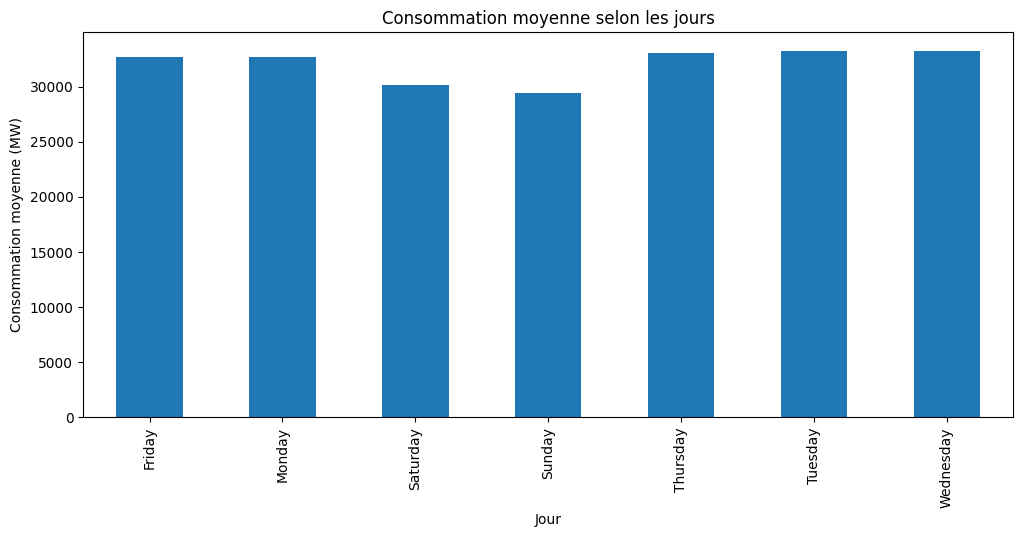

In [218]:
plt.figure(figsize=(12,5))

consumption_day.plot(kind='bar')

plt.title("Consommation moyenne selon les jours")
plt.xlabel("Jour")
plt.ylabel("Consommation moyenne (MW)")

plt.show()

In [ ]:
# Étudier la consommation selon les mois
# df['Month'] = df.index.month

In [220]:
df

,PJME_MW,Hour,DayOfWeek,Month,Year,IsWeekend,Day,Day_Name
Datetime,,,,,,,,
2002-12-31 01:00:00,26498.0,1,1,12,2002,0,1,Tuesday
2002-12-31 02:00:00,25147.0,2,1,12,2002,0,1,Tuesday
2002-12-31 03:00:00,24574.0,3,1,12,2002,0,1,Tuesday
2002-12-31 04:00:00,24393.0,4,1,12,2002,0,1,Tuesday
2002-12-31 05:00:00,24860.0,5,1,12,2002,0,1,Tuesday
...,...,...,...,...,...,...,...,...
2018-01-01 20:00:00,44284.0,20,0,1,2018,0,0,Monday
2018-01-01 21:00:00,43751.0,21,0,1,2018,0,0,Monday
2018-01-01 22:00:00,42402.0,22,0,1,2018,0,0,Monday


In [221]:
consumption_month = df.groupby('Month')['PJME_MW'].mean()

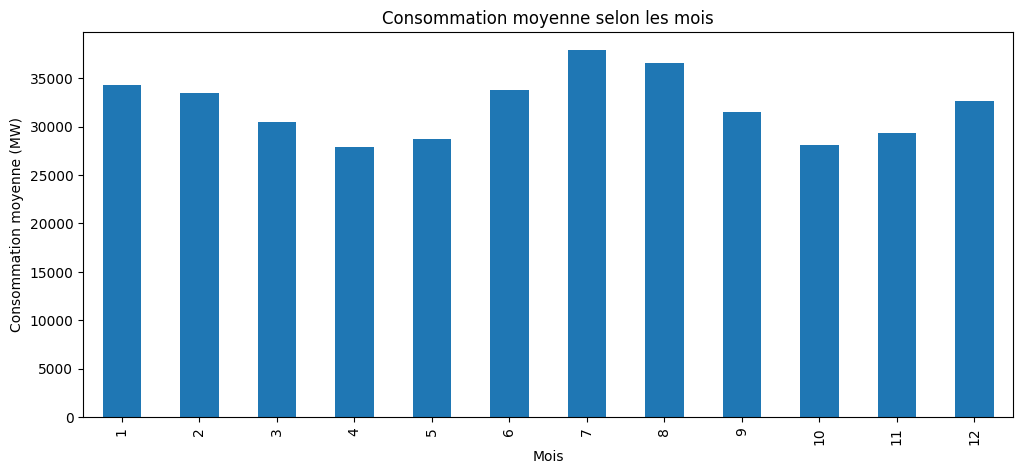

In [222]:
plt.figure(figsize=(12,5))

consumption_month.plot(kind='bar')

plt.title("Consommation moyenne selon les mois")
plt.xlabel("Mois")
plt.ylabel("Consommation moyenne (MW)")

plt.show()

In [223]:
# Identifier les tendances et saisonnalités
# Rolling Mean
df['Rolling_Mean'] = df['PJME_MW'].rolling(window=24*30).mean()

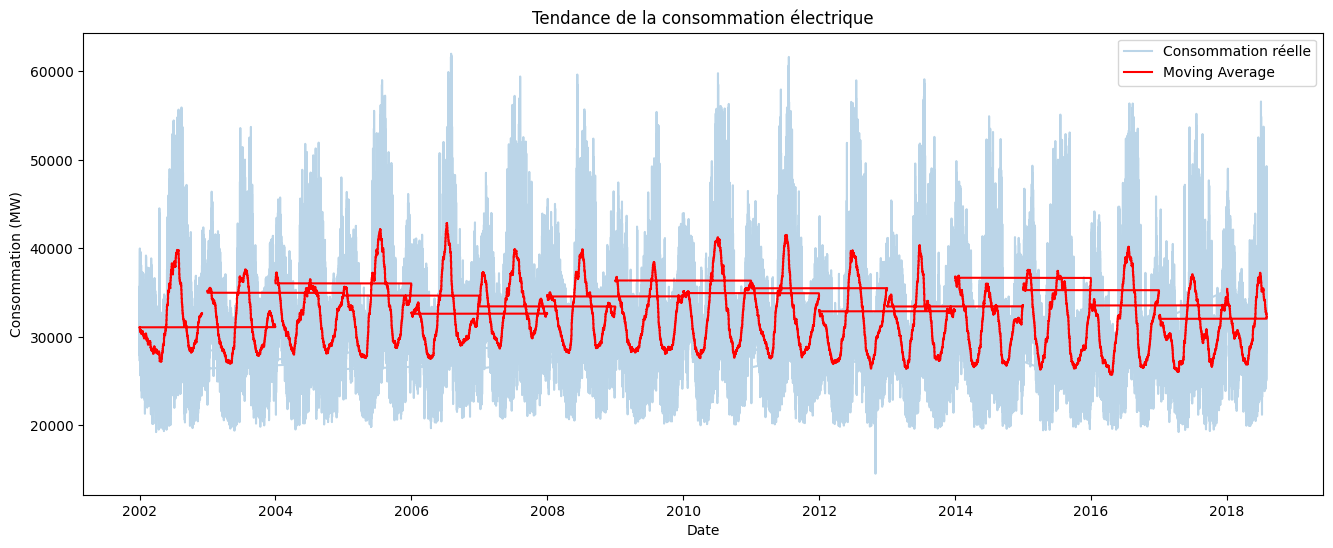

In [224]:
plt.figure(figsize=(16,6))

plt.plot(df.index, df['PJME_MW'], label='Consommation réelle', alpha=0.3)

plt.plot(df.index, df['Rolling_Mean'], label='Moving Average', color='red')

plt.title("Tendance de la consommation électrique")
plt.xlabel("Date")
plt.ylabel("Consommation (MW)")

plt.legend()
plt.show()

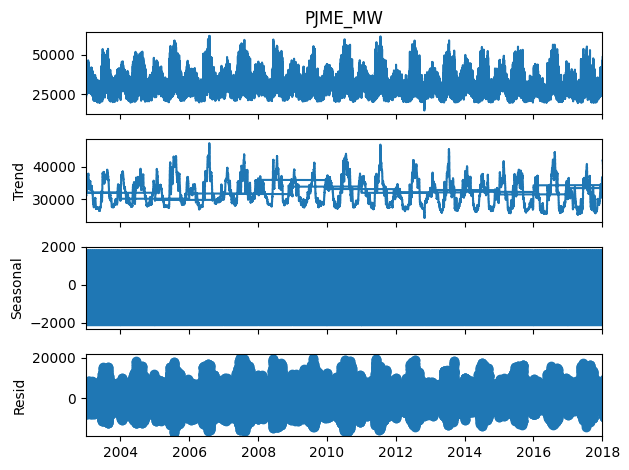

In [225]:
# Analyse de saisonnalité
from statsmodels.tsa.seasonal import seasonal_decompose

result = seasonal_decompose(
    df['PJME_MW'],
    model='additive',
    period=24*7
)

result.plot()
plt.show()

In [226]:
# Créer les variables de retard (Lags)
df['lag_24'] = df['PJME_MW'].shift(24)

df['lag_168'] = df['PJME_MW'].shift(168)

df['lag_168']

,lag_168
Datetime,
2002-12-31 01:00:00,NaN
2002-12-31 02:00:00,NaN
2002-12-31 03:00:00,NaN
2002-12-31 04:00:00,NaN
2002-12-31 05:00:00,NaN
...,...
2018-01-01 20:00:00,42112.0
2018-01-01 21:00:00,40797.0
2018-01-01 22:00:00,38819.0


In [227]:
#  Calculer une moyenne glissante (Rolling Mean)
df['roll_24'] = df['PJME_MW'].shift(1).rolling(window=24).mean()
df=df.dropna()

In [234]:


nominal_features = [
    'Hour',
    'DayOfWeek',
    'Month'
]

numerical_features = [
    'Year',
    'IsWeekend',
    'lag_24',
    'lag_168',
    'roll_24'
]

feature_cols = numerical_features + nominal_features

X = df[feature_cols]
y = df['PJME_MW']



split_index = int(len(X) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]




nominal_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore',
        drop='first'
    ))
])



numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])




preprocessor = ColumnTransformer([
    ('num', numerical_pipeline, numerical_features),
    ('nominal', nominal_pipeline, nominal_features)
])



model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])



model.fit(X_train, y_train)


y_pred = model.predict(X_test)

print("Training completed successfully!")
print("Predictions:", y_pred[:10])


Training completed successfully!
Predictions: [35965.3393034  36728.85535835 37309.17040842 37798.3153544
 38295.35266726 38509.68395714 37931.59769576 37859.41247776
 37245.15960506 35801.20324146]


In [231]:
df

,PJME_MW,Hour,DayOfWeek,Month,Year,IsWeekend,Day,Day_Name,Rolling_Mean,lag_24,lag_168,roll_24
Datetime,,,,,,,,,,,,
2002-12-03 00:00:00,29231.0,0,1,12,2002,0,1,Tuesday,32654.300000,33816.0,34221.0,33173.500000
2002-12-01 01:00:00,26033.0,1,6,12,2002,1,6,Sunday,32653.654167,27811.0,29193.0,32982.458333
2002-12-01 02:00:00,25077.0,2,6,12,2002,1,6,Sunday,32653.556944,26964.0,28124.0,32908.375000
2002-12-01 03:00:00,24622.0,3,6,12,2002,1,6,Sunday,32653.623611,26593.0,27500.0,32829.750000
2002-12-01 04:00:00,24558.0,4,6,12,2002,1,6,Sunday,32653.852778,26603.0,27266.0,32747.625000
...,...,...,...,...,...,...,...,...,...,...,...,...
2018-01-01 20:00:00,44284.0,20,0,1,2018,0,0,Monday,35398.340278,45787.0,42112.0,40406.125000
2018-01-01 21:00:00,43751.0,21,0,1,2018,0,0,Monday,35404.794444,45209.0,40797.0,40343.500000
2018-01-01 22:00:00,42402.0,22,0,1,2018,0,0,Monday,35411.837500,43663.0,38819.0,40282.750000


In [232]:
print(X_train.columns.tolist())

['Day', 'Year', 'IsWeekend', 'lag_24', 'lag_168', 'roll_24', 'Hour', 'DayOfWeek', 'Month']


In [237]:
# 6.4. Évaluation avec les métriques

# Prédictions Baseline
y_pred_baseline = X_test['lag_24']
# Fonction d'évaluation
def evaluate_model(y_true, y_pred):

    mae = mean_absolute_error(y_true, y_pred)

    rmse = np.sqrt(mean_squared_error(y_true, y_pred))

    r2 = r2_score(y_true, y_pred)

    mape = mean_absolute_percentage_error(
        y_true, y_pred
    ) * 100

    return {
        'MAE': mae,
        'RMSE': rmse,
        'R2': r2,
        'MAPE (%)': mape
    }


# Évaluation Linear Regression
results_lr = evaluate_model(y_test, y_pred)

# Évaluation Baseline
results_baseline = evaluate_model(
    y_test, y_pred_baseline
)

# Comparaison
results = pd.DataFrame(
    [results_baseline, results_lr],
    index=['Baseline (lag_24)', 'Linear Regression']
)

results

,MAE,RMSE,R2,MAPE (%)
Baseline (lag_24),2282.525510,3124.619746,0.771403,7.162458
Linear Regression,1823.909935,2443.664826,0.860183,5.769996


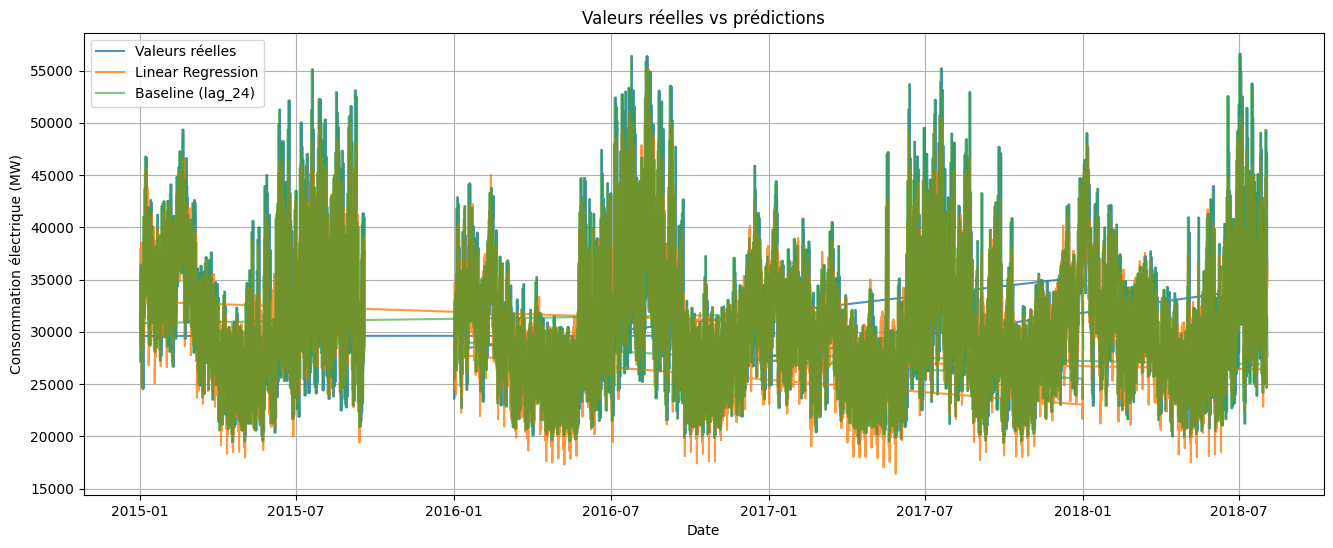

In [240]:
plt.figure(figsize=(16, 6))

plt.plot(
    y_test.index,
    y_test.values,
    label='Valeurs réelles',
    alpha=0.8
)

plt.plot(
    y_test.index,
    y_pred,
    label='Linear Regression',
    alpha=0.8
)

plt.plot(
    y_test.index,
    y_pred_baseline.values,
    label='Baseline (lag_24)',
    alpha=0.6
)

plt.title('Valeurs réelles vs prédictions')
plt.xlabel('Date')
plt.ylabel('Consommation électrique (MW)')

plt.legend()
plt.grid()
plt.show()

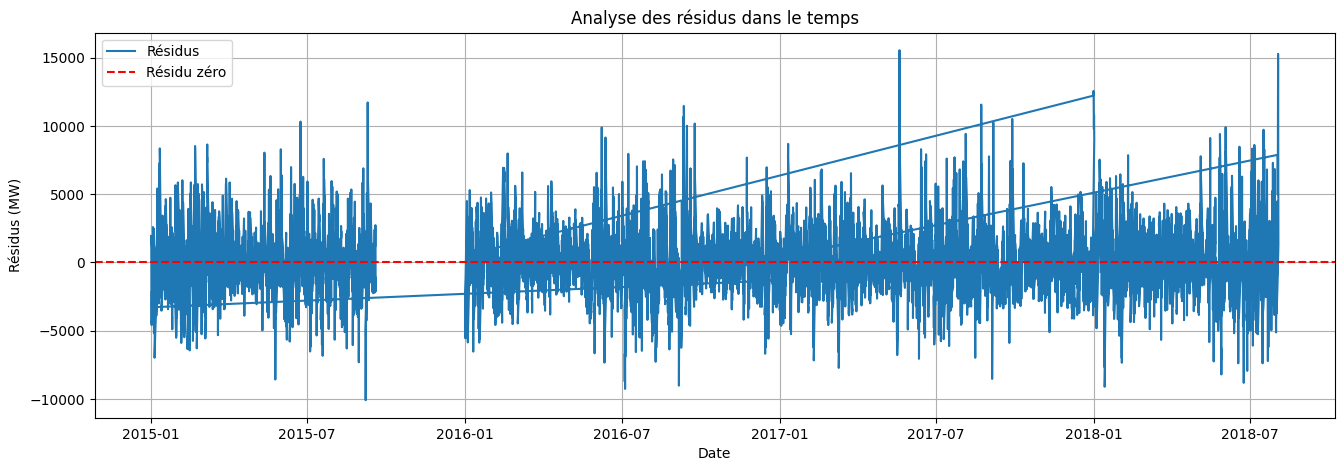

In [242]:
# Analyse des résidus (Residual Analysis)
# Résidu positif : le modèle a sous-estimé la consommation.
# Résidu négatif : le modèle a surestimé la consommation.
# Résidu proche de zéro : la prédiction est proche de la réalité.
# Calcul des résidus
residuals = y_test - y_pred

# Visualisation des résidus dans le temps
plt.figure(figsize=(16, 5))

plt.plot(
    residuals.index,
    residuals.values,
    label='Résidus'
)

plt.axhline(
    y=0,
    color='red',
    linestyle='--',
    label='Résidu zéro'
)

plt.title('Analyse des résidus dans le temps')
plt.xlabel('Date')
plt.ylabel('Résidus (MW)')

plt.legend()
plt.grid()
plt.show()

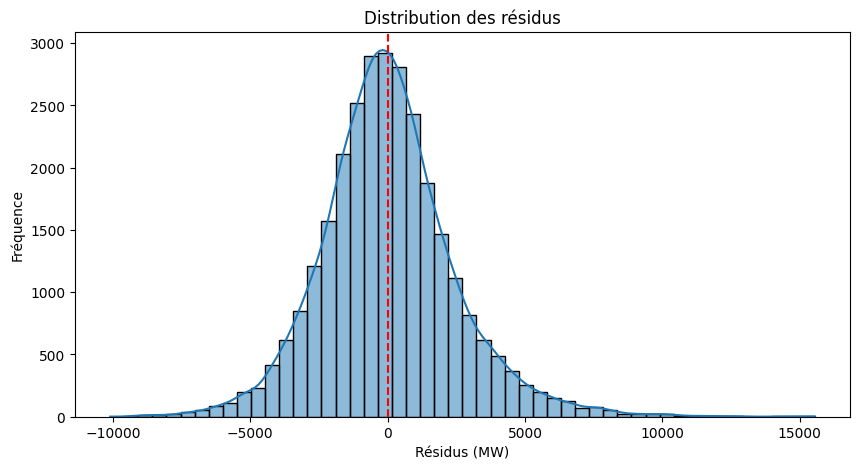

In [243]:
# Distribution des résidus
plt.figure(figsize=(10, 5))

sns.histplot(
    residuals,
    bins=50,
    kde=True
)

plt.axvline(
    x=0,
    color='red',
    linestyle='--'
)

plt.title('Distribution des résidus')
plt.xlabel('Résidus (MW)')
plt.ylabel('Fréquence')

plt.show()

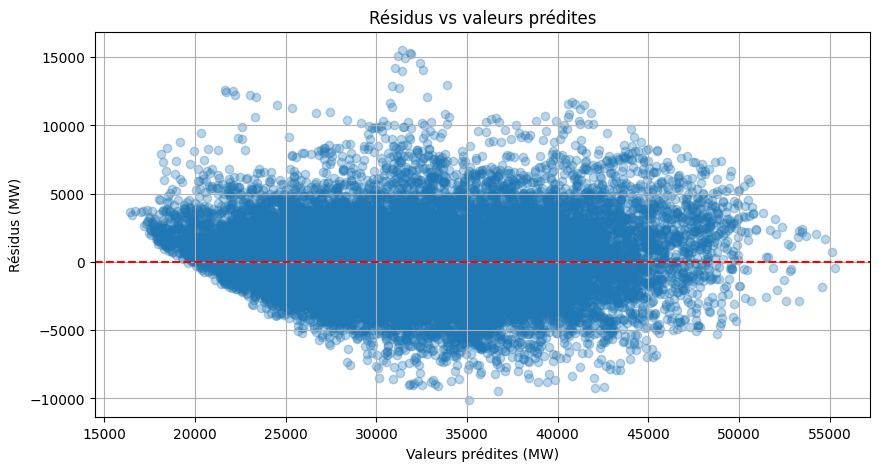

In [244]:
# Résidus vs valeurs prédites
plt.figure(figsize=(10, 5))

plt.scatter(
    y_pred,
    residuals,
    alpha=0.3
)

plt.axhline(
    y=0,
    color='red',
    linestyle='--'
)

plt.title('Résidus vs valeurs prédites')
plt.xlabel('Valeurs prédites (MW)')
plt.ylabel('Résidus (MW)')

plt.grid()
plt.show()